Part 4C: The intercept as a performance drag

**Question.** Annualize the regression intercept (multiply by 252 trading days). Does it roughly align with the stated net operating expense ratio of 1.15% per annum? Name two other expenses that may be reflected in the drag.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.4f}".format

DATA = next(Path("../../data/raw").glob("*part 4*.xlsx"))
FIG = Path("../../output/figures"); FIG.mkdir(parents=True, exist_ok=True)
TAB = Path("../../output/tables"); TAB.mkdir(parents=True, exist_ok=True)

raw = pd.read_excel(DATA, header=None, skiprows=5, names=["date", "NVDA", "NVDL"])
raw["date"] = pd.to_datetime(raw["date"])
df = raw.sort_values("date").set_index("date")
print(len(df), "trading days,", df.index.min().date(), "to", df.index.max().date())

147 trading days, 2024-02-01 to 2024-08-30


In [2]:
import statsmodels.api as sm

ols = sm.OLS(df["NVDL"], sm.add_constant(df["NVDA"])).fit()
a = ols.params["const"]; lo, hi = ols.conf_int(0.05).loc["const"]

summary = pd.DataFrame({
    "Daily": [a, lo, hi],
    "Annualized (x252)": [a * 252, lo * 252, hi * 252],
}, index=["Intercept estimate", "95% CI low", "95% CI high"])
summary.to_csv(TAB / "4C_alpha.csv")
print(summary.apply(lambda col: col.map(lambda v: f"{v:.4%}")).to_string())

# Model-free cross-check: average daily gap between NVDL and exactly twice NVDA
gap = (df["NVDL"] - 2 * df["NVDA"]).mean()
print(f"\nCross-check, mean(NVDL - 2*NVDA) x 252 = {gap * 252:.2%}")

                       Daily Annualized (x252)
Intercept estimate  -0.0612%         -15.4134%
95% CI low          -0.0935%         -23.5523%
95% CI high         -0.0289%          -7.2745%

Cross-check, mean(NVDL - 2*NVDA) x 252 = -15.94%


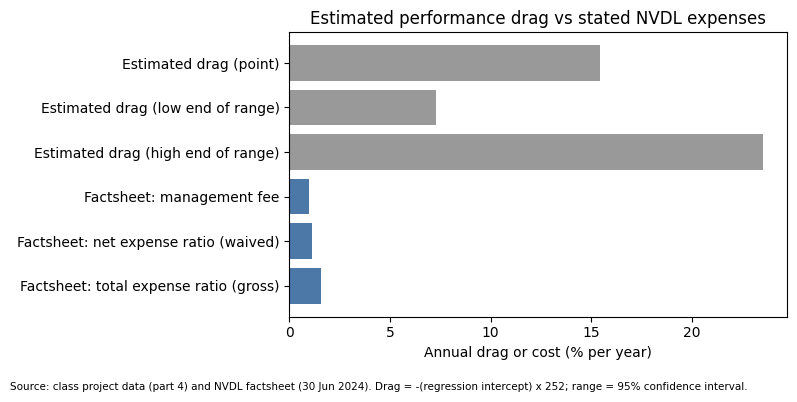

In [3]:
compare = pd.DataFrame({
    "Annual cost / drag": [-a * 252, -hi * 252, -lo * 252, 0.0099, 0.0115, 0.0157],
}, index=["Estimated drag (point)", "Estimated drag (low end of range)", "Estimated drag (high end of range)",
          "Factsheet: management fee", "Factsheet: net expense ratio (waived)", "Factsheet: total expense ratio (gross)"])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(compare.index[::-1], compare["Annual cost / drag"][::-1] * 100,
        color=["#999", "#999", "#999", "#4C78A8", "#4C78A8", "#4C78A8"][::-1])
ax.set_xlabel("Annual drag or cost (% per year)")
ax.set_title("Estimated performance drag vs stated NVDL expenses")
fig.text(0.01, -0.04, "Source: class project data (part 4) and NVDL factsheet (30 Jun 2024). Drag = -(regression intercept) x 252; "
         "range = 95% confidence interval.", fontsize=7.5)
plt.tight_layout(); fig.savefig(FIG / "4C_drag_vs_expense.png", bbox_inches="tight"); plt.show()